# ECE 3715 Mini-Project 1

## Probability, Bayes, and Discrete Random Variables
Professor: Dr. Nir Regev

Team Members: Brandon Chie, Octavio Reyna, William Hsu

Start Date: September 18, 2026

Due Date: October 9, 2026
## Objective
Use probability theory and Python simulations to analyze a wireless communication link. Each bit is independently corrupted by the channel with probability $p$. We will determine how these corrupted bits affect packet errors and retransmissions.

In [14]:
import time #Used for the timer function
import numpy #Used for easy array manipulation functions & RNG
from scipy import stats #Used for theoretical probabilities of binomial, poisson and geometric distribution
import matplotlib.pyplot as plt #Used for plotting graphs
import mp1lib as func #Functions from mp1lib.py file

T_START = time.time()     #Timer begins for total notebook time

SEED = 17                  #Our chosen seed number to keep rng consistent
rng = numpy.random.default_rng(SEED)
rng1, rng2, rng3, rng4, rng5, rng6, rng7, rng8 = rng.spawn(8)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [26]:
#Handcheckable Test
#Assert confirms that the comparison is true, if not assert error will pop up

#For testing purposes we will use a different rng so it doesn't interfere with our current one
rng_test = numpy.random.default_rng(20)

#Setting a test array to test BSC function
b = numpy.array([0, 1, 0, 1, 0, 1, 1])
#Testing array with 0% probability, no bits will get corrupted
assert numpy.array_equal(func.bsc(b, 0, rng_test), b) #array_equal checks if both arrays are equal to each other and outputs t/f
#Testing array with 100% probability, will flip bit array
assert numpy.array_equal(func.bsc(b, 1, rng_test), 1 - b) #1-b Preforms a bit flip
print("BSC Test:        ", b ,"\n0% Probability:  ",func.bsc(b, 0, rng_test), "\n100% Probability:",func.bsc(b, 1.0, rng_test))

#Packet Error Test
#Testing packet error with 0% probability, each packet should contain 0 errors
assert numpy.all(func.packet_errors(5, 1000, 0, rng_test) == 0)
#Testing packet error with 100% probability, each packet should contain max amount of errors
assert numpy.all(func.packet_errors(5, 1000, 1.0, rng_test) == 1000)
print("Packet Errors Test:\n" "0% probability:  ", func.packet_errors(5, 1000, 0, rng_test), "\n100% probability:", func.packet_errors(5, 1000, 1, rng_test))

#Clean Attempt Test
#Testing attempts until clean with 100% probability of successful transmission, all test should be 1
assert numpy.all(func.attempts_until_clean(5, 1, rng_test) == 1)
#Testing 100,000 trials to make sure that our minimum attempt is 1 not 0, if not assert error will occur
assert func.attempts_until_clean(100000, 0.1, rng_test).min() >= 1
print("Clean Attempts Test:\n""q=1:", func.attempts_until_clean(5, 1, rng_test))

#TV Distance Test
#Identical test should have a 0 distance
assert func.tv_distance([0.2, 0.3, 0.5],[0.2, 0.3, 0.5]) == 0
#Complete opposite test should have max distance
assert func.tv_distance([1, 0, 0],[0, 0, 1]) == 1

print("TV Distance Test:\n""Identical distributions:",func.tv_distance([0.2, 0.3, 0.5], [0.2, 0.3, 0.5]),"\nOpposite distributions: ",
    func.tv_distance([1, 0, 0], [0, 0, 1]))

print("\nAll functions work as expected!")

BSC Test:         [0 1 0 1 0 1 1] 
0% Probability:   [0 1 0 1 0 1 1] 
100% Probability: [1 0 1 0 1 0 0]
Packet Errors Test:
0% probability:   [0 0 0 0 0] 
100% probability: [1000 1000 1000 1000 1000]
Clean Attempts Test:
q=1:  [1 1 1 1 1]
TV Distance Test:
Identical distributions: 0.0 
Opposite distributions:  1.0

All functions work as expected!


## Step 1: Sample Space and Probability Axioms

We consider a 4-bit packet where each bit is independently corrupted with
probability $p=0.1$. A corrupted bit is represented by 1, and an
uncorrupted bit is represented by 0.

The three events are:

- $A$: at least one error among the first two bits.
- $B$: exactly two errors in the packet.
- $C$: the fourth bit is corrupted.

There are $2^4=16$ possible error patterns. The probability of a pattern
with $k$ errors is

$$
P(\text{pattern})=p^k(1-p)^{4-k}.
$$

In [3]:
from itertools import product

p_step1 = 0.1

# Enumerate all 16 possible four-bit error patterns
patterns = numpy.array(list(product([0, 1], repeat=4)))

# Count the number of errors in each pattern
number_of_errors = patterns.sum(axis=1)

# Calculate the exact probability of each pattern
pattern_probabilities = (
    p_step1 ** number_of_errors
    * (1 - p_step1) ** (4 - number_of_errors)
)

print("Number of patterns:", len(patterns))
print("Sum of exact probabilities:", pattern_probabilities.sum())

Number of patterns: 16
Sum of exact probabilities: 0.9999999999999999


In [4]:
# Define the three events

# A: at least one error among the first two bits
A = patterns[:, 0:2].any(axis=1)

# B: exactly two errors in the entire packet
B = patterns.sum(axis=1) == 2

# C: the fourth bit is corrupted
C = patterns[:, 3] == 1

# Calculate exact event probabilities
P_A = pattern_probabilities[A].sum()
P_B = pattern_probabilities[B].sum()
P_C = pattern_probabilities[C].sum()

print(f"P(A) = {P_A:.4f}")
print(f"P(B) = {P_B:.4f}")
print(f"P(C) = {P_C:.4f}")

P(A) = 0.1900
P(B) = 0.0486
P(C) = 0.1000


### Exact Event Intersections

The pairwise intersections are found by requiring two events to occur
simultaneously. The triple intersection requires all three events to occur.

$$
P(A\cap B), \quad P(A\cap C), \quad P(B\cap C)
$$

and

$$
P(A\cap B\cap C).
$$

In [5]:
# Calculate exact intersection probabilities

P_AB = pattern_probabilities[A & B].sum()
P_AC = pattern_probabilities[A & C].sum()
P_BC = pattern_probabilities[B & C].sum()
P_ABC = pattern_probabilities[A & B & C].sum()

print(f"P(A and B) = {P_AB:.4f}")
print(f"P(A and C) = {P_AC:.4f}")
print(f"P(B and C) = {P_BC:.4f}")
print(f"P(A and B and C) = {P_ABC:.4f}")

P(A and B) = 0.0405
P(A and C) = 0.0190
P(B and C) = 0.0243
P(A and B and C) = 0.0162


### Inclusion-Exclusion

The probability that at least one of the events occurs is calculated using
the inclusion-exclusion formula:

$$
P(A\cup B\cup C)
=
P(A)+P(B)+P(C)
-P(A\cap B)-P(A\cap C)-P(B\cap C)
+P(A\cap B\cap C).
$$

In [6]:
# Calculate the union directly
P_union_direct = pattern_probabilities[A | B | C].sum()

# Calculate the union using inclusion-exclusion
P_union_inclusion_exclusion = (
    P_A + P_B + P_C
    - P_AB - P_AC - P_BC
    + P_ABC
)

print(f"P(A or B or C), direct = {P_union_direct:.4f}")
print(
    f"P(A or B or C), inclusion-exclusion = "
    f"{P_union_inclusion_exclusion:.4f}"
)

P(A or B or C), direct = 0.2710
P(A or B or C), inclusion-exclusion = 0.2710


### Monte Carlo Simulation

We now estimate the event probabilities by simulating $N=10^6$ four-bit
packets. Each bit is independently corrupted with probability $p=0.1$.
The simulated probabilities are calculated as the fraction of packets for
which each event occurs.

For an estimated probability $\hat{P}$, the standard error is

$$
SE=\sqrt{\frac{\hat{P}(1-\hat{P})}{N}}.
$$

In [7]:
# Monte Carlo simulation
N = 1_000_000

# Start with packets containing no errors, then apply the BSC
simulated_patterns = func.bsc(
    numpy.zeros((N, 4), dtype=int),
    p_step1,
    rng1
)

# Define simulated events
sim_A = simulated_patterns[:, 0:2].any(axis=1)
sim_B = simulated_patterns.sum(axis=1) == 2
sim_C = simulated_patterns[:, 3] == 1

# Simulated intersections and union
sim_AB = sim_A & sim_B
sim_AC = sim_A & sim_C
sim_BC = sim_B & sim_C
sim_ABC = sim_A & sim_B & sim_C
sim_union = sim_A | sim_B | sim_C

# Event names
event_names = [
    "A",
    "B",
    "C",
    "A and B",
    "A and C",
    "B and C",
    "A and B and C",
    "A or B or C"
]

# Exact probabilities
exact_values = numpy.array([
    P_A,
    P_B,
    P_C,
    P_AB,
    P_AC,
    P_BC,
    P_ABC,
    P_union_inclusion_exclusion
])

# Empirical probabilities
empirical_values = numpy.array([
    sim_A.mean(),
    sim_B.mean(),
    sim_C.mean(),
    sim_AB.mean(),
    sim_AC.mean(),
    sim_BC.mean(),
    sim_ABC.mean(),
    sim_union.mean()
])

# Standard errors and differences
standard_errors = numpy.sqrt(
    empirical_values * (1 - empirical_values) / N
)

differences = numpy.abs(empirical_values - exact_values)

print(f"{'Event':<15} {'Exact':>10} {'Empirical':>12} "
      f"{'Difference':>12} {'SE':>12} {'Within 3 SE':>14}")

for name, exact, empirical, difference, se in zip(
    event_names,
    exact_values,
    empirical_values,
    differences,
    standard_errors
):
    print(
        f"{name:<15} {exact:>10.4f} {empirical:>12.4f} "
        f"{difference:>12.4e} {se:>12.4e} "
        f"{difference <= 3 * se!s:>14}"
    )

Event                Exact    Empirical   Difference           SE    Within 3 SE
A                   0.1900       0.1905   4.9600e-04   3.9269e-04           True
B                   0.0486       0.0487   1.0800e-04   2.1526e-04           True
C                   0.1000       0.1001   7.4000e-05   3.0010e-04           True
A and B             0.0405       0.0407   2.1000e-04   1.9762e-04           True
A and C             0.0190       0.0191   1.0400e-04   1.3689e-04           True
B and C             0.0243       0.0242   5.1000e-05   1.5382e-04           True
A and B and C       0.0162       0.0163   5.1000e-05   1.2644e-04           True
A or B or C         0.2710       0.2715   4.6600e-04   4.4472e-04           True


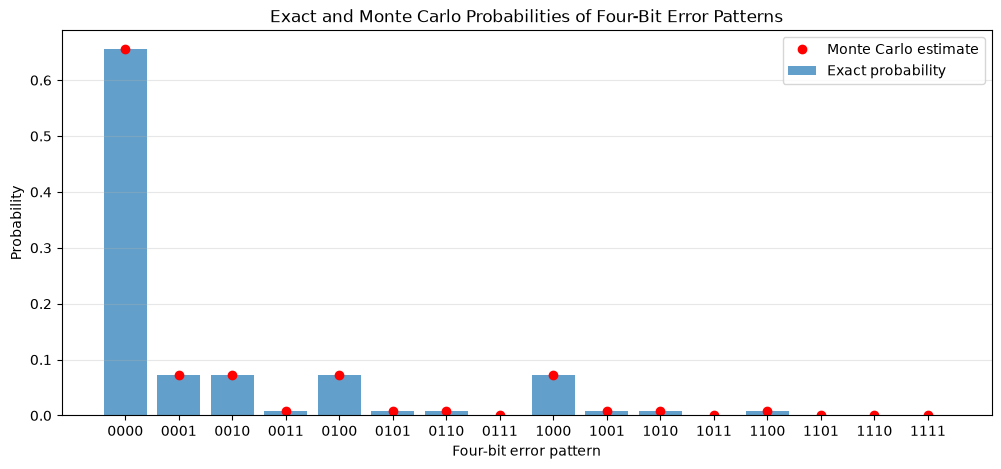

Maximum absolute difference: 0.000455


In [8]:
# Calculate simulated probability for each of the 16 patterns

pattern_labels = [
    "".join(str(bit) for bit in pattern)
    for pattern in patterns
]

# Convert each four-bit pattern to an index from 0 to 15
pattern_indices = simulated_patterns @ numpy.array([8, 4, 2, 1])

# Count simulated occurrences and divide by N
simulated_pattern_probabilities = (
    numpy.bincount(pattern_indices, minlength=16) / N
)

# Plot exact probabilities as bars
x = numpy.arange(16)

plt.figure(figsize=(12, 5))

plt.bar(
    x,
    pattern_probabilities,
    alpha=0.7,
    label="Exact probability"
)

plt.plot(
    x,
    simulated_pattern_probabilities,
    "o",
    color="red",
    label="Monte Carlo estimate"
)

plt.xticks(x, pattern_labels)
plt.xlabel("Four-bit error pattern")
plt.ylabel("Probability")
plt.title("Exact and Monte Carlo Probabilities of Four-Bit Error Patterns")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

max_difference = numpy.max(
    numpy.abs(pattern_probabilities - simulated_pattern_probabilities)
)

print(f"Maximum absolute difference: {max_difference:.6f}")

### Figure 1 Interpretation

The exact probabilities are shown by the bars, while the red markers show
the Monte Carlo estimates from \(10^6\) simulated packets. The estimates
closely follow the exact probabilities for all 16 error patterns. Small
differences occur because the simulation uses a finite number of random
packets. The maximum absolute difference was reported above.

### Standard Error and Step 1 Conclusion

For an event estimated using $N$ simulated packets, the standard error of
the estimated probability is

$$
SE=\sqrt{\frac{\hat{P}(1-\hat{P})}{N}},
$$

where $\hat{P}$ is the simulated probability and

$$
N=10^6.
$$

The exact and empirical probabilities are close for all of the individual
events, intersections, and their union. The comparison table shows that every
absolute difference is within three standard errors of the theoretical value.
Therefore, the Monte Carlo simulator agrees with the exact probability
calculations.

The inclusion-exclusion result also agrees with the direct union calculation:

$$
P(A\cup B\cup C)=0.2710.
$$

This confirms that the event definitions and the probability calculations are
consistent.

## Step 2: Conditional Probability and Bayes' Theorem

The flagging circuit raises a flag with probability $0.95$ when a bit is
actually corrupted. It also raises a false flag with probability $0.02$ when
the bit is not corrupted.

The prior probability that a bit is corrupted is $p$.

Therefore,

$$
P(\text{flag} \mid \text{error})=0.95
$$

and

$$
P(\text{flag} \mid \text{no error})=0.02.
$$

### Derivation of the Posterior Probability

We want to calculate the probability that a bit is actually corrupted given
that the flagging circuit raises a flag.

Using Bayes' theorem,

$$
P(\text{error}\mid\text{flag})
=
\frac{
P(\text{flag}\mid\text{error})P(\text{error})
}{
P(\text{flag})
}.
$$

The total probability of receiving a flag is

$$
P(\text{flag})
=
P(\text{flag}\mid\text{error})P(\text{error})
+
P(\text{flag}\mid\text{no error})P(\text{no error}).
$$

Since $P(\text{error})=p$ and $P(\text{no error})=1-p$,

$$
P(\text{flag})
=
0.95p+0.02(1-p).
$$

Therefore, the posterior probability is

$$
P(\text{error}\mid\text{flag})
=
\frac{0.95p}
{0.95p+0.02(1-p)}.
$$

In [9]:
def posterior_error_given_flag(p):
    """Return P(error | flag) for a given prior error probability p."""
    return (0.95 * p) / (0.95 * p + 0.02 * (1 - p))


for p_value in [0.1, 0.01, 0.001]:
    posterior = posterior_error_given_flag(p_value)
    print(f"p = {p_value:.3f}, P(error | flag) = {posterior:.4f}")

p = 0.100, P(error | flag) = 0.8407
p = 0.010, P(error | flag) = 0.3242
p = 0.001, P(error | flag) = 0.0454


### Posterior Probability as a Function of the Prior

The posterior probability changes as the prior bit-error probability $p$
changes. The horizontal axis will use a logarithmic scale because the prior
varies from $10^{-4}$ to $10^{-1}$.

Crossover p = 0.0206
Posterior at crossover = 0.5000


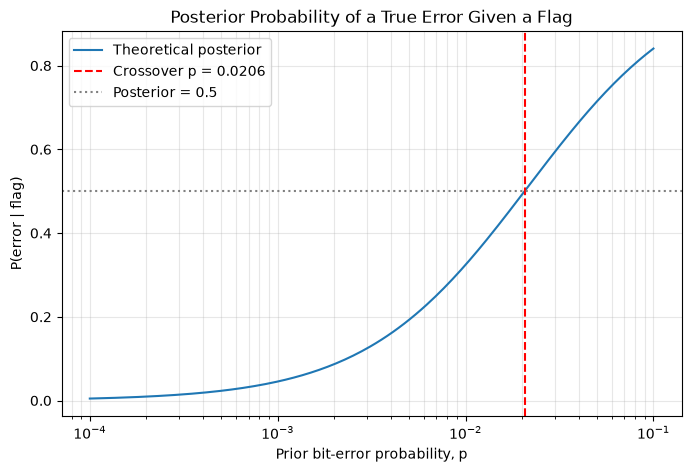

In [10]:
# Prior probabilities from 10^-4 to 10^-1
p_grid = numpy.logspace(-4, -1, 200)

# Calculate the posterior for every prior probability
posterior_values = posterior_error_given_flag(p_grid)

# Solve P(error | flag) = 0.5
p_crossover = 0.02 / (0.95 + 0.02)
posterior_crossover = posterior_error_given_flag(p_crossover)

print(f"Crossover p = {p_crossover:.4f}")
print(f"Posterior at crossover = {posterior_crossover:.4f}")

plt.figure(figsize=(8, 5))

plt.semilogx(
    p_grid,
    posterior_values,
    label="Theoretical posterior"
)

plt.axvline(
    p_crossover,
    color="red",
    linestyle="--",
    label=f"Crossover p = {p_crossover:.4f}"
)

plt.axhline(
    0.5,
    color="gray",
    linestyle=":",
    label="Posterior = 0.5"
)

plt.xlabel("Prior bit-error probability, p")
plt.ylabel("P(error | flag)")
plt.title("Posterior Probability of a True Error Given a Flag")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

### Monte Carlo 

The theoretical crossover occurs when

$$
P(\text{error}\mid\text{flag})=0.5.
$$

Solving this equation gives

$$
0.5=
\frac{0.95p}{0.95p+0.02(1-p)}.
$$

Multiplying both sides by the denominator,

$$
0.5\left[0.95p+0.02(1-p)\right]=0.95p.
$$

This simplifies to

$$
0.02(1-p)=0.95p,
$$

so

$$
p=\frac{0.02}{0.95+0.02}
\approx 0.0206.
$$

We now verify this result by simulating $10^7$ bits.

In [11]:
# Monte Carlo verification of the crossover
N_bayes = 10_000_000

# Use the crossover probability
true_errors = rng2.random(N_bayes) < p_crossover

# The flag probability depends on whether an actual error occurred
flag_probabilities = numpy.where(
    true_errors,
    0.95,
    0.02
)

flags = rng2.random(N_bayes) < flag_probabilities

# Count flags and flags that correspond to true errors
number_of_flags = flags.sum()
number_of_true_error_flags = numpy.sum(flags & true_errors)

# Empirical posterior
posterior_estimate = (
    number_of_true_error_flags / number_of_flags
)

# Standard error of the conditional proportion
posterior_standard_error = numpy.sqrt(
    posterior_estimate
    * (1 - posterior_estimate)
    / number_of_flags
)

print(f"Number of flags: {number_of_flags}")
print(f"True-error flags: {number_of_true_error_flags}")
print(f"Empirical posterior: {posterior_estimate:.4f}")
print(f"Standard error: {posterior_standard_error:.4e}")
print(f"Theoretical posterior: {posterior_crossover:.4f}")

Number of flags: 391747
True-error flags: 195596
Empirical posterior: 0.4993
Standard error: 7.9885e-04
Theoretical posterior: 0.5000


In [14]:
# Add the Monte Carlo estimate and error bar to the posterior plot

plt.figure(figsize=(8, 5))

plt.semilogx(
    p_grid,
    posterior_values,
    label="Theoretical posterior"
)

plt.axvline(
    p_crossover,
    color="red",
    linestyle="--",
    label=f"Crossover p = {p_crossover:.4f}"
)

plt.axhline(
    0.5,
    color="gray",
    linestyle=":",
    label="Posterior = 0.5"
)

plt.errorbar(
    p_crossover,
    posterior_estimate,
    yerr=posterior_standard_error,
    fmt="o",
    color="black",
    capsize=5,
    label="Monte Carlo estimate"
)

plt.xlabel("Prior bit-error probability, p")
plt.ylabel("P(error | flag)")
plt.title("Bayes Posterior Probability and Monte Carlo Verification")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

NameError: name 'plt' is not defined

### Conclusion

Although the flagging circuit detects $95\%$ of actual errors, a flag does not
always mean that an error occurred. When the link is very reliable, actual
errors are rare, so false flags can make up a large portion of all flags. For
example, when $p=0.001$, the probability that a flagged bit is actually
corrupted is only about $0.0453$. Therefore, the prior error rate must be
considered when interpreting a flag.

## Step 3: Independence

This step examines pairwise independence, mutual independence, and
conditional independence.

### Part 1: Pairwise and Mutual Independence

Two fair coins are flipped. Define the events:

- $E_1$: the first coin lands heads.
- $E_2$: the second coin lands heads.
- $E_3$: the two coins match.

Each event has probability

$$
P(E_1)=P(E_2)=P(E_3)=\frac{1}{2}.
$$

For pairwise independence, we compare the joint probabilities with the
products of the individual probabilities:

$$
P(E_1\cap E_2)=P(E_1)P(E_2),
$$

$$
P(E_1\cap E_3)=P(E_1)P(E_3),
$$

and

$$
P(E_2\cap E_3)=P(E_2)P(E_3).
$$

However,

$$
P(E_1\cap E_2\cap E_3)=\frac{1}{4},
$$

while

$$
P(E_1)P(E_2)P(E_3)
=
\frac{1}{2}\frac{1}{2}\frac{1}{2}
=
\frac{1}{8}.
$$

Therefore, the events are pairwise independent but not mutually
independent.

In [13]:
# Part 1: two fair coins
N_coins = 1_000_000

coin_flips = rng3.integers(
    0,
    2,
    size=(N_coins, 2)
)

E1 = coin_flips[:, 0] == 1
E2 = coin_flips[:, 1] == 1
E3 = coin_flips[:, 0] == coin_flips[:, 1]

P_E1 = E1.mean()
P_E2 = E2.mean()
P_E3 = E3.mean()

P_E1E2 = (E1 & E2).mean()
P_E1E3 = (E1 & E3).mean()
P_E2E3 = (E2 & E3).mean()
P_E1E2E3 = (E1 & E2 & E3).mean()

print(f"P(E1) = {P_E1:.4f}")
print(f"P(E2) = {P_E2:.4f}")
print(f"P(E3) = {P_E3:.4f}")

print("\nPairwise comparisons:")
print(
    f"P(E1)P(E2) = {P_E1 * P_E2:.4f}, "
    f"P(E1 and E2) = {P_E1E2:.4f}"
)
print(
    f"P(E1)P(E3) = {P_E1 * P_E3:.4f}, "
    f"P(E1 and E3) = {P_E1E3:.4f}"
)
print(
    f"P(E2)P(E3) = {P_E2 * P_E3:.4f}, "
    f"P(E2 and E3) = {P_E2E3:.4f}"
)

print("\nTriple comparison:")
print(
    f"P(E1)P(E2)P(E3) = "
    f"{P_E1 * P_E2 * P_E3:.4f}, "
    f"P(E1 and E2 and E3) = {P_E1E2E3:.4f}"
)

P(E1) = 0.5007
P(E2) = 0.4991
P(E3) = 0.4994

Pairwise comparisons:
P(E1)P(E2) = 0.2499, P(E1 and E2) = 0.2496
P(E1)P(E3) = 0.2501, P(E1 and E3) = 0.2496
P(E2)P(E3) = 0.2492, P(E2 and E3) = 0.2496

Triple comparison:
P(E1)P(E2)P(E3) = 0.1248, P(E1 and E2 and E3) = 0.2496


### Part 2: Conditional Independence of Receiver Outputs

A transmitted bit is equally likely to be 0 or 1. Two receivers observe the
bit through independent channels. Receiver 1 has error probability $0.1$, and
Receiver 2 has error probability $0.3$.

The receiver outputs are dependent when the transmitted bit is unknown because
both receivers share the same transmitted bit. However, after conditioning
on the transmitted bit, the channel errors are independent. Therefore, the
conditional correlations should be approximately zero.

In [10]:
# Part 2: two receivers observing the same transmitted bit
N_receivers = 1_000_000

transmitted_bits = rng3.integers(
    0,
    2,
    size=N_receivers
)

receiver_1_errors = rng3.random(N_receivers) < 0.1
receiver_2_errors = rng3.random(N_receivers) < 0.3

receiver_1_output = numpy.bitwise_xor(
    transmitted_bits,
    receiver_1_errors.astype(int)
)

receiver_2_output = numpy.bitwise_xor(
    transmitted_bits,
    receiver_2_errors.astype(int)
)


def correlation_and_standard_error(x, y):
    """Return Pearson correlation and its approximate standard error."""
    correlation = numpy.corrcoef(x, y)[0, 1]
    sample_size = len(x)
    standard_error = (
        1 - correlation**2
    ) / numpy.sqrt(sample_size - 2)
    return correlation, standard_error


# Unconditional correlation
rho_all, se_all = correlation_and_standard_error(
    receiver_1_output,
    receiver_2_output
)

# Correlation conditioned on transmitted bit = 0
mask_zero = transmitted_bits == 0
rho_zero, se_zero = correlation_and_standard_error(
    receiver_1_output[mask_zero],
    receiver_2_output[mask_zero]
)

# Correlation conditioned on transmitted bit = 1
mask_one = transmitted_bits == 1
rho_one, se_one = correlation_and_standard_error(
    receiver_1_output[mask_one],
    receiver_2_output[mask_one]
)

print(f"Unconditional correlation: {rho_all:.4f}")
print(f"Unconditional standard error: {se_all:.4e}")

print(f"\nCorrelation given transmitted bit = 0: {rho_zero:.4f}")
print(f"Standard error given transmitted bit = 0: {se_zero:.4e}")

print(f"\nCorrelation given transmitted bit = 1: {rho_one:.4f}")
print(f"Standard error given transmitted bit = 1: {se_one:.4e}")

print(f"\nSamples with transmitted bit = 0: {mask_zero.sum()}")
print(f"Samples with transmitted bit = 1: {mask_one.sum()}")

NameError: name 'rng3' is not defined

### Part 3: Conclusion

If two sensors share a common cause but are incorrectly assumed to be
independent, a fusion system may become overconfident in its result. It may
count the same information twice and underestimate the uncertainty of its
decision.

## Step 4: Bernoulli Trials and the Binomial

The goal of this step is to get from single bit behavior to packet-level behavior 

In [37]:
def packet_errors(n_pkt, n_bits, p, rng, chunk=10_000):
    """Number of bit errors in each of n_pkt packets of n_bits bits.

    Each bit is in error independently with probability p.
    Simulated at the bit level, in chunks of packets to limit memory.
    Returns an int array of length n_pkt.
    """
    out = numpy.empty(n_pkt, dtype=np.int64)
    for s in range(0, n_pkt, chunk):
        m = min(chunk, n_pkt - s)
        out[s:s+m] = (rng.random((m, n_bits)) < p).sum(axis=1)
    return out

### Why Number of Errors in a 1000-bit Packet is binomial
Each of the n = 1000 bits is a Bernoulli trial that is in error with the same probability p, 
and the channel corrupts bits independently of one another. The error count is therefore a
sum of n i.i.d. Bernoulli(p) variables, which is by definition Binomial(n, p), with pmf 
$P(X=k)=\binom{n}{k}p^k(1-p)^{n-k}$

In [43]:
n, p, N = 1000, 0.005, 10**5
x = packet_errors(N, n, p, rng4)          # rng4 = this step's spawned generator

k = numpy.arange(0, x.max() + 2)
fig, ax = matplotlib.pyplot.subplots()
ax.hist(x, bins=numpy.arange(-0.5, x.max() + 1.5), density=True,
        alpha=0.5, label=f"Simulation (N = {N:,})")
ax.plot(k, scipy.stats.pmf(k, n, p), "o-", label="Binomial(1000, 0.005) pmf")
ax.set_xlabel("Number of bit errors in a packet")
ax.set_ylabel("Probability")
ax.set_title("Figure 3: Packet error count, n = 1000, p = 0.005")
ax.legend()

NameError: name 'np' is not defined

In [44]:
n, p, N = 1000, 0.005, 10**5
x = packet_errors(N, n, p, rng4)          # rng4 = this step's spawned generator

k = numpy.arange(0, x.max() + 2)
fig, ax = matplotlib.pyplot.subplots()
ax.hist(x, bins=numpy.arange(-0.5, x.max() + 1.5), density=True,
        alpha=0.5, label=f"Simulation (N = {N:,})")
ax.plot(k, scipy.stats.pmf(k, n, p), "o-", label="Binomial(1000, 0.005) pmf")
ax.set_xlabel("Number of bit errors in a packet")
ax.set_ylabel("Probability")
ax.set_title("Figure 3: Packet error count, n = 1000, p = 0.005")
ax.legend()

NameError: name 'np' is not defined